# Longitudinal champion proficiency and specialization

Offline exploratory analysis of the saved NA Ranked Solo/Duo cohort, patch 16.19. The question is when champion-specific experience might offset a population matchup disadvantage. Repeated player observations and nonrandom champion choices make this **descriptive observational research**, not an estimate of the effect of switching champions in the same game.

This notebook reads saved Parquet tables, local metadata/checkpoints and selected cached JSONs. It never instantiates a collector or API client, loads credentials, scrapes, changes source data, or fits final models. Run all cells with Python, pandas, NumPy, PyArrow, matplotlib, nbformat/IPython and the repository helpers available. All dates below are UTC. No installation or network access is required.

## 1. Snapshot, schema, and definitions

Select the latest timestamped snapshot whose five Parquet inputs and metadata are readable and structurally valid. Incomplete *collection* is retained for inspection and does not invalidate a saved snapshot. Repository paths resolve from either the root or `hlr_model/`.

In [1]:
from pathlib import Path
import sys, json, re, hashlib
from collections import Counter
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents]
             if (p / 'hlr_model/longitudinal_pipeline.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or hlr_model/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hlr_model.longitudinal_pipeline import Config, expanding_features, RECORD_COLUMNS
from hlr_model.riot_api_helpers import read_json, MatchStore
from lpm_model.otp_match_pipeline import ROLE_MAP

RUN = ROOT / 'hlr_model/data/runs/patch_16_19_seed_1619'
NAMES = ['longitudinal_modeling', 'historical_matches', 'target_matches', 'player_cohort', 'player_coverage']
rejected = []
for candidate in sorted((RUN / 'processed').iterdir(), reverse=True):
    if not candidate.is_dir() or not re.fullmatch(r'\d{8}T\d{12}Z', candidate.name):
        continue
    try:
        frames = {n: pd.read_parquet(candidate / f'{n}.parquet') for n in NAMES}
        meta = read_json(candidate / 'collection_metadata.json')
        config = Config(**meta['config'])
        for n, f in frames.items():
            required = {'puuid'}
            if n in NAMES[:3]:
                required |= set(RECORD_COLUMNS)
            if not required.issubset(f.columns):
                raise ValueError(f'{n}: missing {required - set(f.columns)}')
        if not {'prior_total_games', 'prior_champion_games', 'is_main_champion'}.issubset(frames[NAMES[0]].columns):
            raise ValueError('Missing expanding feature columns')
    except (OSError, ValueError, KeyError, TypeError) as exc:
        rejected.append({'snapshot': candidate.name, 'reason': type(exc).__name__ + ': ' + str(exc)})
        continue
    SNAPSHOT = candidate
    break
else:
    raise FileNotFoundError('No valid saved snapshot found.')
model, history, targets, cohort, coverage = [frames[n].copy() for n in NAMES]
print('Selected snapshot:', SNAPSHOT.relative_to(ROOT))
if rejected:
    display(pd.DataFrame(rejected))
# Fingerprint every snapshot file and the existing helpers; later check no changes.
protected = list(SNAPSHOT.glob('*')) + [ROOT/'hlr_model/longitudinal_pipeline.py',
            ROOT/'hlr_model/riot_api_helpers.py', ROOT/'lpm_model/otp_match_pipeline.py']
source_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in protected if p.is_file()}
checkpoint_path = RUN/'metadata/checkpoint.json'
checkpoint = read_json(checkpoint_path) if checkpoint_path.exists() else None
if checkpoint_path.exists():
    source_hashes[checkpoint_path] = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()

SEED, BOOTSTRAPS = 1619, 1000
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'font.size': 10, 'figure.dpi': 115, 'axes.titleweight': 'bold'})
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 18)
def table(frame, percent=(), decimals=()):
    formats = {c: '{:.1%}' for c in percent if c in frame.columns}
    formats.update({c: '{:.2f}' for c in decimals if c in frame.columns})
    display(frame.style.format(formats, na_rep='—'))
def utc(ms):
    return pd.to_datetime(ms, unit='ms', utc=True)
def span(frame):
    return f'{utc(frame.timestamp.min())} to {utc(frame.timestamp.max())}'

Selected snapshot: hlr_model/data/runs/patch_16_19_seed_1619/processed/20261018T195205790466Z


,table,rows,columns,players
0,longitudinal_modeling,7238,67,185
1,historical_matches,29889,21,185
2,target_matches,7238,21,185
3,player_cohort,200,24,200
4,player_coverage,200,15,200


,longitudinal_modeling,historical_matches,target_matches,player_cohort,player_coverage
anchor_timestamp,float64,—,—,float64,float64
available_historical_matches,int64,—,—,int64,int64
candidate_matches,int64,—,—,int64,int64
champion,object,object,object,—,—
champion_id,int64,int64,int64,—,—
cohort_order,int64,—,—,int64,—
end_timestamp,int64,int64,int64,—,—
genuinely_short_history,bool,—,—,bool,bool
historical_masters_verified,bool,—,—,bool,—
history_discovery_complete,bool,—,—,bool,bool


Initial history kickoff range: 2026-01-09 03:16:29.325000+00:00 to 2026-09-23 11:59:07.809000+00:00


,,rows,players,win_rate
patch,queue,,,
16.1,420,71,5,46.5%
16.10,420,868,54,53.0%
16.11,420,906,59,53.3%
16.12,420,1191,78,54.2%
16.13,420,2750,101,51.8%
16.14,420,1986,114,53.7%
16.15,420,3310,124,53.8%
16.16,420,3978,141,53.3%
16.17,420,6038,173,52.2%


Targets kickoff range: 2026-09-23 12:20:17.734000+00:00 to 2026-10-07 08:33:21.723000+00:00


,,rows,players,win_rate
patch,queue,,,
16.19,420,7238,185,50.5%


Sampled: 200; represented: 185; target player-games: 7,238; unique target matches: 6,806.
Target wins: 3,652; losses: 3,586; win rate: 50.5%.


,target_games
0.00,1.0
0.10,5.0
0.25,14.0
0.50,27.0
0.75,58.0
0.90,88.6
0.95,106.6
1.00,197.0


,player,target_games,row_share
0,P077,197,2.7%
1,P009,164,2.3%
2,P197,160,2.2%
3,P086,153,2.1%
4,P072,143,2.0%
5,P118,131,1.8%
6,P089,124,1.7%
7,P175,120,1.7%
8,P106,113,1.6%
9,P019,107,1.5%


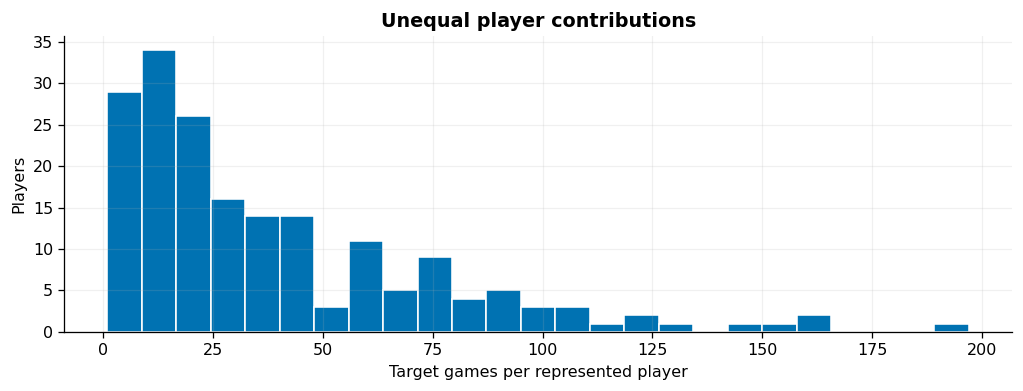

In [2]:
overview = pd.DataFrame([{'table': n, 'rows': len(f), 'columns': f.shape[1],
                         'players': f.puuid.nunique()} for n, f in frames.items()])
display(overview)
# Full schema is compactly arranged rather than printing data records.
schema = pd.DataFrame({n: pd.Series({c: str(t) for c, t in f.dtypes.items()}) for n, f in frames.items()})
with pd.option_context('display.max_rows', 80):
    display(schema.fillna('—'))
for name, f in [('Initial history', history), ('Targets', targets)]:
    print(name, 'kickoff range:', span(f))
    display(f.groupby(['patch', 'queue']).agg(rows=('match_id', 'size'),
            players=('puuid', 'nunique'), win_rate=('win', 'mean')).style.format({'win_rate': '{:.1%}'}))
print(f'Sampled: {len(cohort):,}; represented: {model.puuid.nunique():,}; '
      f'target player-games: {len(model):,}; unique target matches: {model.match_id.nunique():,}.')
print(f'Target wins: {model.win.sum():,}; losses: {model.win.eq(0).sum():,}; win rate: {model.win.mean():.1%}.')
games_per_player = model.groupby('puuid').size()
display(games_per_player.quantile([0, .1, .25, .5, .75, .9, .95, 1]).rename('target_games').to_frame())
# Stable local aliases keep long identifiers out of routine tables.
alias = {p: f'P{i+1:03d}' for i, p in enumerate(cohort.sort_values('cohort_order').puuid)}
contributors = games_per_player.nlargest(10).rename('target_games').to_frame()
contributors['player'] = contributors.index.map(alias)
contributors['row_share'] = contributors.target_games / len(model)
table(contributors.reset_index(drop=True)[['player','target_games','row_share']], percent=['row_share'])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(games_per_player, bins=25, color=BLUE, edgecolor='white')
ax.set(xlabel='Target games per represented player', ylabel='Players', title='Unequal player contributions')
plt.tight_layout(); plt.show()

**Feature semantics from `longitudinal_pipeline.expanding_features`:** the initial history is capped at 170 eligible queue-420 games completed before the first target, within the configured season boundary. Pregame features then expand using that preserved history and earlier targets whose **end timestamps are strictly before kickoff**. The cap does not apply to expanding `prior_total_games`; this is not lifetime experience and is not a rolling 170-game window.

The prior main is the most-used champion in this expanding history; tied counts select the smallest champion ID. Main usage share is main games / all prior games. Selected-champion experience is the prior count for the champion picked now. Raw champion win rate is wins / games (missing at zero games); Beta(1,1) smoothing is `(wins+1)/(games+2)`. Champion win rate minus overall historical win rate is a descriptive proficiency proxy, with an overlapping denominator, not an isolated skill effect.

`is_main_champion` identifies the current pick. The preliminary `is_otp` requires that pick to be the prior main and its usage share to meet the configured threshold, with **no experience minimum**. A specialized player picking an alternative is therefore not `is_otp`; specialization and playing one's main must be separate variables. Main identity and specialization can change over time.

V1 Master seed labels lack dated patch-period verification. Neither match participation nor current rank repairs that gap. `teamPosition` is inferred from postgame play, not verified lane intent before the game; using it as a pregame feature requires care.

In [3]:
print('Historically verified Masters:', int(cohort.historical_masters_verified.sum()), '/', len(cohort))
print('Pipeline preliminary OTP share threshold:', config.otp_share_threshold)
print('Initial cap:', config.historical_depth, '| largest expanding count:', model.prior_total_games.max())

Historically verified Masters: 0 / 200
Pipeline preliminary OTP share threshold: 0.5
Initial cap: 170 | largest expanding count: 366


## 2. Coverage and local collection evidence

A short history means bounded pagination completed with fewer than the requested games; it does not establish lifetime inactivity or complete Riot retention. An incomplete history means collection did not finish. Players with no eligible targets never needed an anchor/history. They contribute to the saved shortfall counter but are not collection failures.

In [4]:
coverage_status = np.select([
    coverage.target_matches.eq(0), coverage.history_incomplete,
    coverage.genuinely_short_history,
    coverage.available_historical_matches.ge(config.historical_depth)],
    ['No eligible targets', 'Incomplete history', 'Genuinely short history', 'Initial depth reached'],
    default='Other / investigate')
cov = coverage.assign(status=coverage_status)
display(cov.groupby('status').agg(players=('puuid','size'), target_rows=('target_matches','sum'),
              history_rows=('available_historical_matches','sum'),
              saved_shortfalls=('history_shortfall',lambda x: x.gt(0).sum())))
print('Saved shortfall counter:', coverage.history_shortfall.gt(0).sum())
display(coverage.groupby(['history_stop_reason','target_discovery_complete',
                         'history_discovery_complete'], dropna=False).size().rename('players').to_frame())
print('Missing required cached payloads:', coverage.missing_required_payloads.sum())
# Only display the safe failure fields written by RiotRequestError, never credentials or raw responses.
def safe_failure(f):
    out = {k: f.get(k) for k in ['puuid','stage','match_id','error','at_utc']}
    out['error'] = re.sub(r'RGAPI-[A-Za-z0-9-]+', '[REDACTED]', str(out['error']))
    return out
failure_records = [dict(source='snapshot', **safe_failure(f)) for f in meta.get('failures', [])]
if checkpoint:
    failure_records += [dict(source='checkpoint', **safe_failure(f)) for f in checkpoint.get('failures', [])]
print('Recorded failures by source (attempts may repeat across sources):')
display(pd.DataFrame(failure_records))
incomplete = coverage.loc[coverage.history_incomplete]
with pd.option_context('display.max_colwidth', 90):
    display(incomplete[['puuid','available_historical_matches','target_matches','history_stop_reason',
                        'target_discovery_complete','history_discovery_complete','history_exhausted',
                        'missing_required_payloads']])
if checkpoint:
    snapshot_ids = set(cohort.puuid)
    cp_ids = {x['puuid'] for x in checkpoint['identity']['cohort']}
    print('Checkpoint cohort/config match snapshot:', snapshot_ids == cp_ids,
          checkpoint['identity']['config'] == meta['config'])
    cp_summary = []
    for p in incomplete.puuid:
        state = checkpoint['players'].get(p, {})
        cp_summary.append({'player': alias[p], 'history_ids': len(state.get('history_ids', [])),
            'target_ids': len(state.get('target_ids', [])), 'stop_reason': state.get('history_stop_reason'),
            'history_complete': state.get('history_complete'), 'target_complete': state.get('target_complete')})
    display(pd.DataFrame(cp_summary))
print('Snapshot API counters (historical only):', meta.get('api_metrics_this_session'))

,players,target_rows,history_rows,saved_shortfalls
status,,,,
Genuinely short history,25,878,2740,25
Incomplete history,1,5,119,1
Initial depth reached,159,6355,27030,0
No eligible targets,15,0,0,15


Saved shortfall counter: 41


,,,players
history_stop_reason,target_discovery_complete,history_discovery_complete,
api_exhausted_within_season,True,True,25
collection_error,True,False,1
historical_depth_reached,True,True,159
not_started,True,False,15


Missing required cached payloads: 0
Recorded failures by source (attempts may repeat across sources):


,source,puuid,stage,match_id,error,at_utc
0,snapshot,uAuVBtm3_Xg4SvoGg-tttr10Lc_irF8M4MdlpdLJP6C7w2...,history_discovery_or_detail,None,Incomplete/mismatched Riot match payload.,2026-10-18T13:51:04.688318+00:00
1,checkpoint,uAuVBtm3_Xg4SvoGg-tttr10Lc_irF8M4MdlpdLJP6C7w2...,history_discovery_or_detail,None,Incomplete/mismatched Riot match payload.,2026-10-18T13:51:04.688318+00:00


,puuid,available_historical_matches,target_matches,history_stop_reason,target_discovery_complete,history_discovery_complete,history_exhausted,missing_required_payloads
80,uAuVBtm3_Xg4SvoGg-tttr10Lc_irF8M4MdlpdLJP6C7w2g9_tnJWeZr5cp4bq3Nbzmot2eXhYHXEQ,119,5,collection_error,True,False,False,0


Checkpoint cohort/config match snapshot: True True


,player,history_ids,target_ids,stop_reason,history_complete,target_complete
0,P081,119,5,collection_error,False,True


Snapshot API counters (historical only): {'http_attempts': 29836, 'transient_retries': 6}


The recorded incomplete-history error is **“Incomplete/mismatched Riot match payload.”** `MatchStore.get` raises this when a fetched payload fails its structural/match-ID validation, before saving it. The failure record has no match ID and does not retain the rejected response. Local evidence establishes the validation failure, but **cannot establish the offending match, malformed field, or upstream cause**. Preserved partial history remains usable only with its incompleteness disclosed; compare results with and without this player as a sensitivity analysis. No retry or repair is attempted here.

In [5]:
store = MatchStore(RUN/'raw/matches', [ROOT/'data/otp_raw_matches', ROOT/'lpm_model/data/otp_raw_matches'])
missing = targets.loc[targets.matchup_missing].copy()
print('Rows with unidentified lane opponent:', len(missing))
display(missing[['match_id','champion','team_position','lane','opponent_champion']])
role_evidence, participant_evidence = [], []
for row in missing.itertuples():
    payload = store.get(row.match_id, download=False)
    if payload is None:
        role_evidence.append({'match_id': row.match_id, 'champion': row.champion, 'cause': 'Unresolved: cache unavailable'})
        continue
    participants = payload['info']['participants']
    focal = next(p for p in participants if p.get('puuid') == row.puuid)
    role = focal.get('teamPosition')
    own = [p for p in participants if p.get('teamId') == focal['teamId'] and p.get('teamPosition') == role]
    opposing = [p for p in participants if p.get('teamId') == 300-focal['teamId'] and p.get('teamPosition') == role]
    cause = ('Focal teamPosition blank/unrecognized' if role not in ROLE_MAP else
             'No opposing participant assigned the focal teamPosition' if len(opposing)==0 else
             'Nonunique focal/opposing role assignment' if len(own)!=1 or len(opposing)!=1 else
             'Opponent champion name absent')
    role_evidence.append({'match_id': row.match_id, 'champion': row.champion,
        'focal_teamPosition': repr(role), 'focal_individualPosition': focal.get('individualPosition'),
        'same_role_own': len(own), 'same_role_opposing': len(opposing), 'cause': cause})
    for p in participants:
        participant_evidence.append({'match_id': row.match_id, 'champion': p.get('championName'),
            'team': p.get('teamId'), 'teamPosition': p.get('teamPosition'),
            'individualPosition': p.get('individualPosition'), 'lane': p.get('lane'), 'role': p.get('role')})
with pd.option_context('display.max_colwidth', 80):
    display(pd.DataFrame(role_evidence))
# Forty compact role rows, not raw JSON: all participants establish presence/absence of roles.
with pd.option_context('display.max_rows', 45):
    display(pd.DataFrame(participant_evidence))

Rows with unidentified lane opponent: 4


,match_id,champion,team_position,lane,opponent_champion
1944,NA1_5654656307,TwistedFate,,None,None
3204,NA1_5651645059,Leona,,None,None
6605,NA1_5647518697,Senna,,None,None
6609,NA1_5648218433,Viktor,BOTTOM,adc,None


,match_id,champion,focal_teamPosition,focal_individualPosition,same_role_own,same_role_opposing,cause
0,NA1_5654656307,TwistedFate,'',Invalid,1,0,Focal teamPosition blank/unrecognized
1,NA1_5651645059,Leona,'',Invalid,1,0,Focal teamPosition blank/unrecognized
2,NA1_5647518697,Senna,'',Invalid,1,0,Focal teamPosition blank/unrecognized
3,NA1_5648218433,Viktor,'BOTTOM',BOTTOM,1,0,No opposing participant assigned the focal teamPosition


,match_id,champion,team,teamPosition,individualPosition,lane,role
0,NA1_5654656307,Jayce,100,TOP,TOP,NONE,SUPPORT
1,NA1_5654656307,Graves,100,JUNGLE,JUNGLE,NONE,SUPPORT
2,NA1_5654656307,Akali,100,MIDDLE,MIDDLE,NONE,SUPPORT
3,NA1_5654656307,Ashe,100,BOTTOM,BOTTOM,NONE,SUPPORT
4,NA1_5654656307,Seraphine,100,UTILITY,UTILITY,NONE,SUPPORT
5,NA1_5654656307,Darius,200,TOP,TOP,NONE,SUPPORT
6,NA1_5654656307,Shyvana,200,JUNGLE,JUNGLE,NONE,SUPPORT
7,NA1_5654656307,TwistedFate,200,,Invalid,NONE,SUPPORT
8,NA1_5654656307,Jinx,200,BOTTOM,BOTTOM,NONE,SUPPORT
9,NA1_5654656307,Alistar,200,UTILITY,UTILITY,NONE,SUPPORT


The pipeline identifies an opponent only when the focal `teamPosition` is recognized and uniquely occupied on **both** teams. Cached JSONs confirm three blank focal positions (`individualPosition = Invalid`) and, for Viktor's BOTTOM row, no opposing BOTTOM assignment. The other team includes an invalid position. This establishes why the algorithm left the opponent missing; it does not establish the true lane encounter or why Riot inferred an invalid role. Alternative `lane`/`role` fields do not resolve these cases. No champion is guessed.

Keep these rows for overall player/champion experience and win summaries. Exclude them explicitly from analyses requiring a known lane opponent or matchup disadvantage; lane summaries naturally exclude missing lanes, while Viktor still has a known focal lane. Known-opponent rows lacking external statistics are a different missingness category.

## 3. Integrity and strict time ordering

The audit uses the saved records, an independent per-target reconstruction, and the existing pure feature helper. Passing reconstruction proves consistency with **preserved** records and eligibility rules, not that omitted API history never existed. All failures are displayed; unavailable evidence is reported rather than counted as a pass.

In [6]:
checks = []
def check(name, ok, details=''):
    checks.append({'check': name, 'status': 'PASS' if bool(ok) else 'FAIL', 'details': str(details)})
keys = ['puuid','match_id']
for name, f in [('history',history),('targets',targets),('modeling',model)]:
    check(name + ': unique player/match', not f.duplicated(keys).any())
    check(name + ': binary outcome', f.win.isin([0,1]).all())
    check(name + ': queue and valid duration', f.queue.eq(config.queue).all() & f.end_timestamp.ge(f.timestamp).all())
check('Target patch', targets.patch.eq(config.target_patch).all())
a = targets.set_index(keys).sort_index()
b = model.set_index(keys).sort_index()[a.columns]
check('All target record fields agree with modeling', a.equals(b), f'{len(a):,} rows, {len(a.columns)} fields')
check('Cohort / coverage unique, represented players sampled', not cohort.puuid.duplicated().any()
      and not coverage.puuid.duplicated().any() and set(model.puuid) <= set(cohort.puuid))
counts = coverage.set_index('puuid')
check('Coverage counts equal preserved history/targets',
      counts.available_historical_matches.equals(history.groupby('puuid').size().reindex(counts.index,fill_value=0).rename('available_historical_matches'))
      and counts.target_matches.equals(targets.groupby('puuid').size().reindex(counts.index,fill_value=0).rename('target_matches')))
check('No within-player initial/target overlap', not (set(map(tuple,history[keys].values)) & set(map(tuple,targets[keys].values))))
anchors = targets.groupby('puuid').timestamp.min()
check('Initial history completed before first target', history.end_timestamp.lt(history.puuid.map(anchors)).all())
check('Initial history bounded by season and cap', history.timestamp.ge(config.season_start*1000).all()
      and history.groupby('puuid').size().le(config.historical_depth).all())
check('Targets in frozen search window', targets.timestamp.ge(config.target_search_start*1000).all()
      and targets.timestamp.lt(meta['search_end']*1000).all())
check('Latest prior completion strictly before kickoff',
      (model.prior_latest_end_timestamp.isna() | model.prior_latest_end_timestamp.lt(model.timestamp)).all())
for prefix in ['total','champion','main_champion','other_champion']:
    n, w = model[f'prior_{prefix}_games'], model[f'prior_{prefix}_wins']
    check(prefix + ': nonnegative integer counts / valid wins',
          (n.ge(0) & w.ge(0) & w.le(n) & n.le(model.prior_total_games) & n.mod(1).eq(0) & w.mod(1).eq(0)).all())
rate_cols = [c for c in model if c.startswith('prior_') and (c.endswith('_wr') or c.endswith('_beta11') or c.endswith('_usage_share'))]
check('Rates and shares within [0,1] or missing', all(model[c].dropna().between(0,1).all() for c in rate_cols))
check('Raw selected WR missing exactly for zero experience', model.prior_champion_wr.isna().equals(model.prior_champion_games.eq(0)))
check('Expanding total counts nondecreasing', all(g.prior_total_games.diff().dropna().ge(0).all()
       for _,g in model.sort_values(['timestamp','match_id']).groupby('puuid')))

# Independent direct filtering, not the helper's incremental cursor algorithm.
# Use precisely season-bounded preserved initial history plus completed targets, queue 420.
expected = []
for p, g in targets.groupby('puuid'):
    pool = pd.concat([history.loc[history.puuid.eq(p)], g], ignore_index=True).drop_duplicates(keys)
    pool = pool.loc[pool.queue.eq(config.queue) & pool.timestamp.ge(config.season_start*1000)]
    for r in g.itertuples():
        prior = pool.loc[pool.end_timestamp.lt(r.timestamp) & pool.timestamp.lt(r.timestamp)]
        chosen = prior.loc[prior.champion_id.eq(r.champion_id)]
        expected.append({'puuid': p, 'match_id': r.match_id,
            'prior_total_games': len(prior), 'prior_total_wins': prior.win.sum(),
            'prior_champion_games': len(chosen), 'prior_champion_wins': chosen.win.sum(),
            'prior_latest_end_timestamp': prior.end_timestamp.max(),
            'self_included': prior.match_id.eq(r.match_id).any()})
independent = pd.DataFrame(expected).set_index(keys).sort_index()
for c in ['prior_total_games','prior_total_wins','prior_champion_games','prior_champion_wins','prior_latest_end_timestamp']:
    saved = model.set_index(keys).sort_index()[c]
    good = np.isclose(saved, independent[c], equal_nan=True)
    check('Independent reconstruction: '+c, good.all(), f'{(~good).sum()} disagreements')
check('Current game never in its own eligible pool', not independent.self_included.any())
rebuilt = expanding_features(history, targets, config).set_index(keys).sort_index()
try:
    pd.testing.assert_frame_equal(model.set_index(keys).sort_index()[rebuilt.columns], rebuilt, check_dtype=False)
    check('Pure helper reconstructs every saved record/feature', True, f'{len(rebuilt.columns)} fields')
except AssertionError as exc:
    check('Pure helper reconstructs every saved record/feature', False, str(exc)[:300])
# Counterfactual audit: flip one outcome in memory; its own pregame features must stay identical.
p = games_per_player.idxmax()
test_targets = targets.loc[targets.puuid.eq(p)].sort_values(['timestamp','match_id']).copy()
first_id = test_targets.iloc[0].match_id
base = expanding_features(history.loc[history.puuid.eq(p)], test_targets, config).set_index('match_id')
test_targets.loc[test_targets.match_id.eq(first_id),'win'] = 1-test_targets.loc[test_targets.match_id.eq(first_id),'win']
flipped = expanding_features(history.loc[history.puuid.eq(p)], test_targets, config).set_index('match_id')
features = [c for c in base if c.startswith('prior_') or c.startswith('is_')]
check('Outcome perturbation leaves its own pregame features unchanged', base.loc[first_id,features].equals(flipped.loc[first_id,features]))
display(pd.DataFrame(checks))
print('Audit failures:', sum(x['status']=='FAIL' for x in checks))
shared = model.groupby('match_id').agg(player_rows=('puuid','size'),players=('puuid','nunique'), starts=('timestamp','nunique'))
print(f'Shared target matches: {shared.players.gt(1).sum():,}; player rows in these matches: '
      f'{shared.loc[shared.players.gt(1),"player_rows"].sum():,}; largest focal-player count: {shared.players.max()}.')
print('Shared-match kickoff disagreement count:', shared.starts.gt(1).sum())

,check,status,details
0,history: unique player/match,PASS,
1,history: binary outcome,PASS,
2,history: queue and valid duration,PASS,
3,targets: unique player/match,PASS,
4,targets: binary outcome,PASS,
...,...,...,...
28,Independent reconstruction: prior_champion_wins,PASS,0 disagreements
29,Independent reconstruction: prior_latest_end_t...,PASS,0 disagreements
30,Current game never in its own eligible pool,PASS,
31,Pure helper reconstructs every saved record/fe...,PASS,42 fields


Audit failures: 0
Shared target matches: 410; player rows in these matches: 842; largest focal-player count: 3.
Shared-match kickoff disagreement count: 0


Cross-player appearances of the same match are legitimate observations. They induce additional team/opponent dependence, including possible opposite outcomes, so a player-only uncertainty calculation cannot fully account for all dependence. Player/match pairs, not match IDs alone, are the observation keys.

## 4. Initial history and decision-time experience

Initial summaries use **one row per player at their first target**, avoiding over-weighting prolific players. All-target summaries describe decision times and are game-weighted. Initial distinct champions are counted in the preserved history, not from future target picks.

,initial_history_games,initial_distinct_champions,prior_main_champion_usage_share
count,185.000,185.000,185.000
mean,161.562,23.043,0.448
std,24.934,15.179,0.282
min,46.000,1.000,0.053
10%,127.800,6.400,0.120
25%,170.000,11.000,0.188
50%,170.000,20.000,0.376
75%,170.000,31.000,0.684
90%,170.000,44.600,0.906
max,170.000,74.000,1.000


,prior_total_games,prior_champion_games,prior_main_champion_usage_share
count,7238.000,7238.000,7238.000
mean,198.017,58.966,0.437
std,42.076,68.588,0.276
min,46.000,0.000,0.053
10%,170.000,1.000,0.121
25%,177.000,6.000,0.194
50%,192.000,25.000,0.360
75%,218.000,102.000,0.683
90%,250.000,170.000,0.899
95%,273.000,196.000,0.933


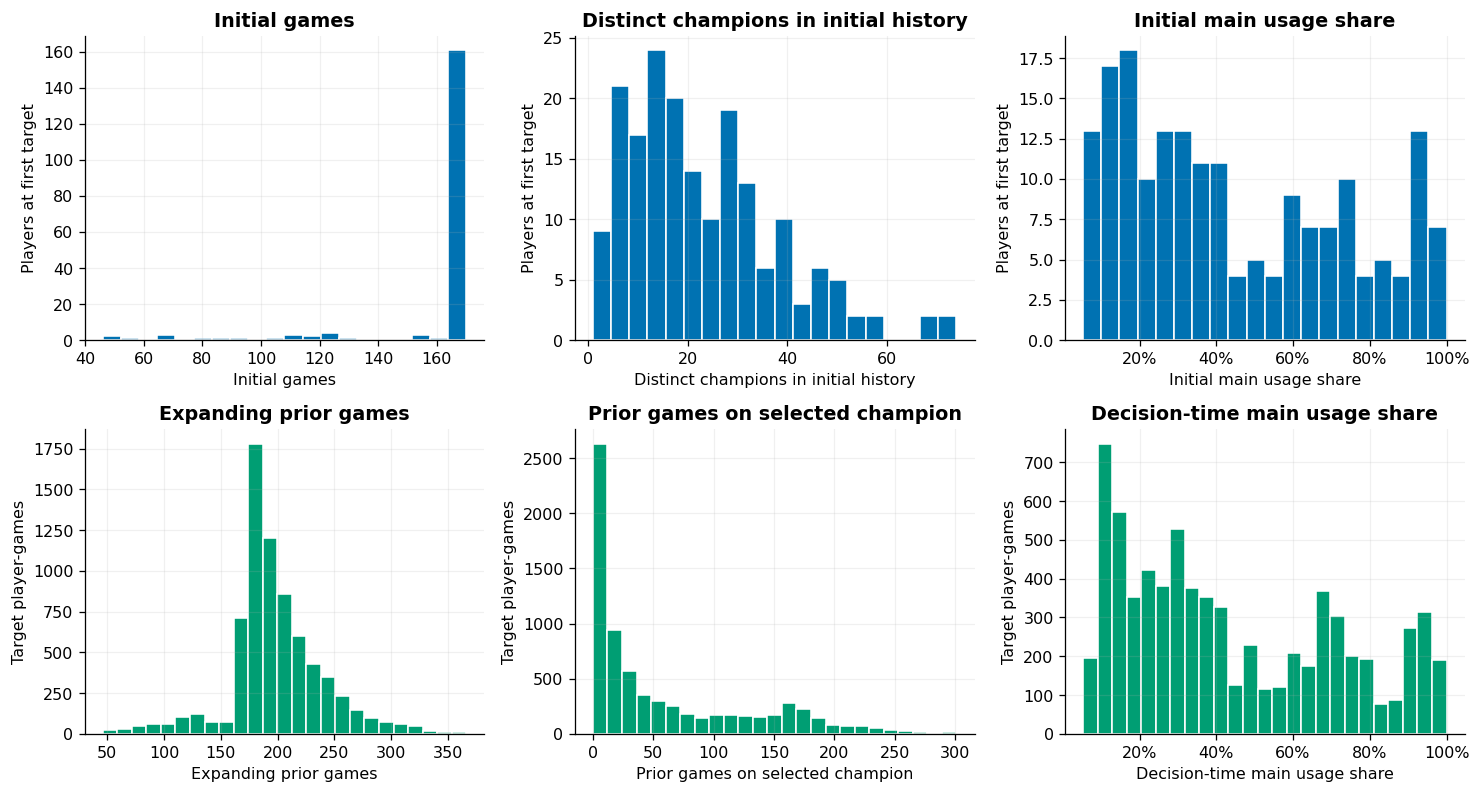

No overall prior history: 0 target rows


,rows,players,main_rows,win_rate
experience_bin,,,,
0,411,123,0,43.6%
1–4,1042,152,0,48.2%
5–9,824,128,7,48.9%
10–19,948,122,42,51.1%
20–29,605,90,101,51.1%
30+,3408,149,2837,52.1%


Raw champion WR unavailable: 411 rows; not silently imputed.


In [7]:
first = model.sort_values(['timestamp','match_id']).groupby('puuid',sort=False).head(1).copy()
first['initial_distinct_champions'] = first.puuid.map(history.groupby('puuid').champion_id.nunique()).fillna(0)
initial_cols = ['initial_history_games','initial_distinct_champions','prior_main_champion_usage_share']
display(first[initial_cols].describe(percentiles=[.1,.25,.5,.75,.9]).round(3))
decision_cols = ['prior_total_games','prior_champion_games','prior_main_champion_usage_share']
display(model[decision_cols].describe(percentiles=[.1,.25,.5,.75,.9,.95]).round(3))
fig, axes = plt.subplots(2,3,figsize=(13,7))
for ax, c, label in zip(axes[0], initial_cols,
        ['Initial games','Distinct champions in initial history','Initial main usage share']):
    ax.hist(first[c].dropna(), bins=20,color=BLUE,edgecolor='white')
    ax.set(title=label, ylabel='Players at first target',xlabel=label)
    if 'share' in c: ax.xaxis.set_major_formatter(PercentFormatter(1))
for ax,c,label in zip(axes[1],decision_cols,
        ['Expanding prior games','Prior games on selected champion','Decision-time main usage share']):
    ax.hist(model[c].dropna(),bins=25,color=GREEN,edgecolor='white')
    ax.set(title=label,ylabel='Target player-games',xlabel=label)
    if 'share' in c: ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
model['pick'] = np.where(model.is_main_champion,'Main','Off-main')
model['experience_bin'] = pd.cut(model.prior_champion_games,[-1,0,4,9,19,29,np.inf],
        labels=['0','1–4','5–9','10–19','20–29','30+'])
model['specialization_bin'] = pd.cut(model.prior_main_champion_usage_share,
        [-np.inf,.4,.5,.6,.7,.8,np.inf],right=False,
        labels=['<40%','40–<50%','50–<60%','60–<70%','70–<80%','80%+'])
model['historical_wr_bin'] = pd.cut(model.prior_champion_wr,[-.001,.4,.5,.6,1],
        labels=['≤40%','>40–50%','>50–60%','>60%'])
model['relative_wr_bin'] = pd.cut(model.prior_champion_wr_minus_overall,
        [-np.inf,-.1,0,.1,np.inf],labels=['≤−10 pp','−10–0 pp','0–10 pp','>10 pp'])
print('No overall prior history:', model.prior_total_games.eq(0).sum(), 'target rows')
experience = model.groupby('experience_bin',observed=True).agg(rows=('win','size'),players=('puuid','nunique'),
            main_rows=('is_main_champion','sum'),win_rate=('win','mean'))
table(experience,percent=['win_rate'])
print('Raw champion WR unavailable:', model.prior_champion_wr.isna().sum(), 'rows; not silently imputed.')

,rows,players,raw_mean,smoothed_mean,raw_extreme_share
experience_bin,,,,,
0,411,123,—,50.0%,—
1–4,1042,152,50.2%,50.4%,52.3%
5–9,824,128,55.6%,54.3%,3.3%
10–19,948,122,55.9%,55.1%,0.1%
20–29,605,90,55.6%,55.2%,0.0%
30+,3408,149,54.7%,54.6%,0.0%


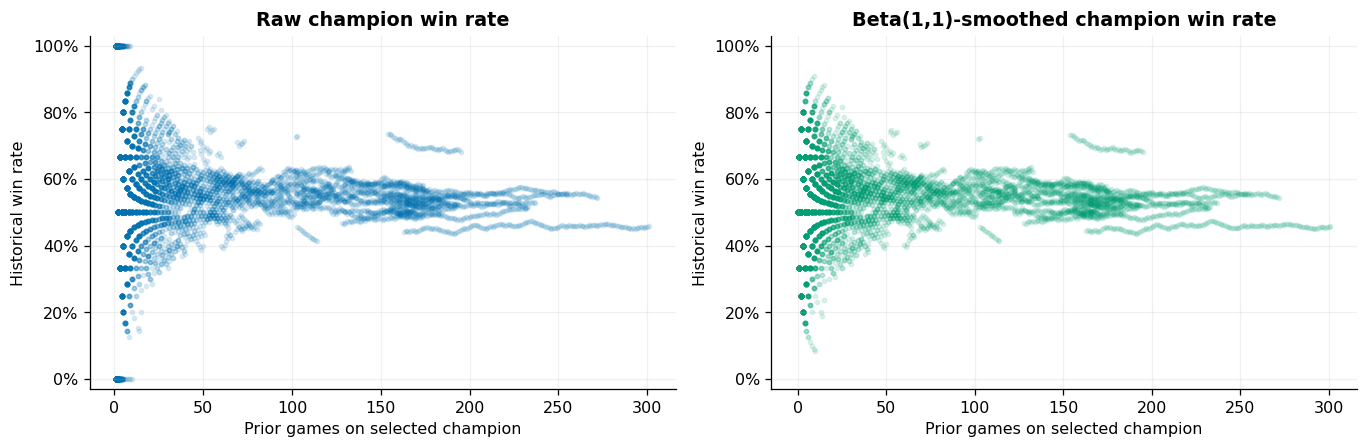

In [8]:
smoothing = model.groupby('experience_bin',observed=True).agg(rows=('win','size'),
    players=('puuid','nunique'), raw_mean=('prior_champion_wr','mean'),
    smoothed_mean=('prior_champion_wr_beta11','mean'),
    raw_extreme_share=('prior_champion_wr',lambda x: x.dropna().isin([0,1]).mean()))
table(smoothing,percent=['raw_mean','smoothed_mean','raw_extreme_share'])
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(model.prior_champion_games,model.prior_champion_wr,s=7,alpha=.12,color=BLUE)
axes[1].scatter(model.prior_champion_games,model.prior_champion_wr_beta11,s=7,alpha=.12,color=GREEN)
for ax,title in zip(axes,['Raw champion win rate','Beta(1,1)-smoothed champion win rate']):
    ax.set(xlabel='Prior games on selected champion',ylabel='Historical win rate',title=title,ylim=(-.03,1.03))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

Smoothing pulls tiny histories away from 0% and 100% (zero games maps to 50% by the prior). It limits extreme estimates; it does **not** make tiny samples reliable or turn 50% into observed evidence. A fixed 30-game “CLT rule” is not appropriate. History size, outcome balance, dependence and the estimand matter.

## 5. Specialization and observed performance

The selected central comparisons use 1,000 player-cluster bootstrap resamples with a fixed seed. Each sampled player brings all their games; the same resample weights are used for main/off-main contrasts. Intervals are descriptive percentile intervals, not causal or multiplicity-adjusted significance tests. Shared matches connect players and remain a limitation of this bootstrap.

Game-weighted rates answer what happened across observed player-games. Equal-player rates average each contributing player's rate **within that category**; categories can still contain different players. The paired switcher comparison below uses players observed in both categories.

,rows,players,win_rate,equal_player_wr,cluster_low,cluster_high
pick,,,,,,
Main,2987,165,51.9%,49.7%,50.2%,53.8%
Off-main,4251,180,49.4%,46.4%,47.9%,51.0%


Game-weighted main minus off-main: 2.50 percentage points; player-cluster 95% interval: [0.20210846 4.84533653].
Players observed in both categories: 160; equal-player within-player descriptive difference: 3.97 pp; 95% cluster interval [-0.54853132  8.37379098].


**Prior main usage**

,rows,players,win_rate,equal_player_wr,cluster_low,cluster_high
specialization_bin,,,,,,
<40%,3989,103,51.3%,49.5%,49.9%,52.6%
40–<50%,588,25,51.7%,54.7%,46.9%,56.3%
50–<60%,387,19,47.0%,46.0%,42.7%,51.8%
60–<70%,664,24,50.0%,51.8%,46.4%,55.3%
70–<80%,588,18,48.6%,53.9%,45.1%,55.2%
80%+,1022,31,49.1%,45.5%,45.6%,52.2%


**Selected-champion experience**

,rows,players,win_rate,equal_player_wr,cluster_low,cluster_high
experience_bin,,,,,,
0,411,123,43.6%,45.2%,38.8%,48.0%
1–4,1042,152,48.2%,44.0%,44.8%,51.6%
5–9,824,128,48.9%,46.3%,45.9%,52.1%
10–19,948,122,51.1%,48.6%,48.0%,53.9%
20–29,605,90,51.1%,43.1%,46.6%,55.3%
30+,3408,149,52.1%,50.9%,50.6%,53.8%


**Raw selected-champion historical WR**

,rows,players,win_rate,equal_player_wr,cluster_low,cluster_high
historical_wr_bin,,,,,,
≤40%,804,143,45.3%,42.9%,41.8%,48.9%
>40–50%,1446,143,50.7%,49.8%,48.3%,53.2%
>50–60%,2897,155,52.0%,49.0%,50.2%,53.9%
>60%,1680,151,51.8%,47.6%,49.3%,54.1%


**Champion WR minus overall historical WR**

,rows,players,win_rate,equal_player_wr,cluster_low,cluster_high
relative_wr_bin,,,,,,
≤−10 pp,833,146,44.4%,42.4%,41.1%,47.9%
−10–0 pp,1293,147,50.7%,49.4%,48.0%,53.7%
0–10 pp,3432,158,52.3%,50.3%,50.7%,54.0%
>10 pp,1269,139,51.4%,48.6%,48.4%,54.0%


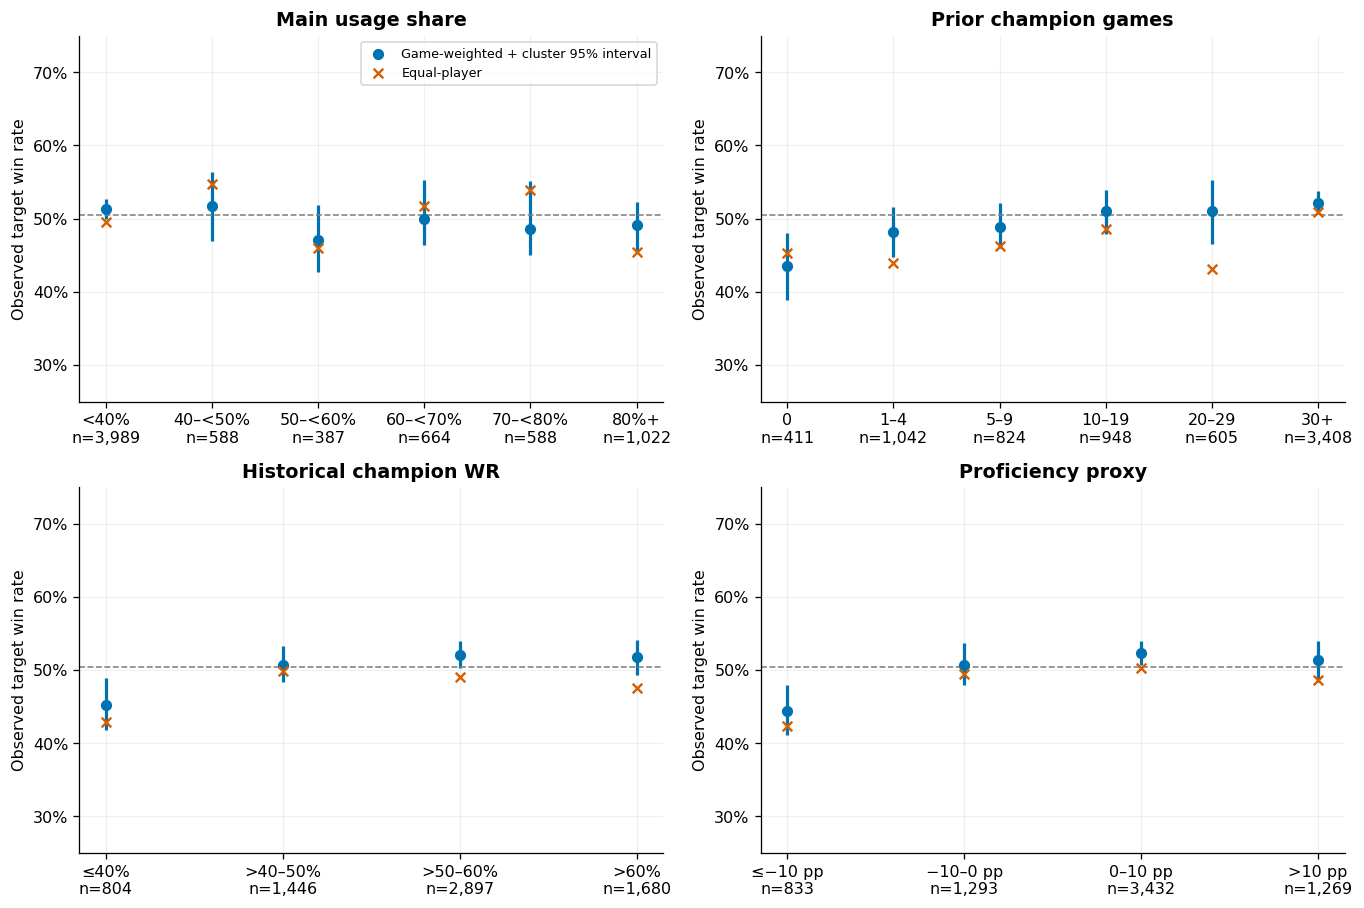

Rows omitted from raw historical-WR/proxy bins due to zero champion experience: 411


In [9]:
def summarize_by(frame, group_col, bootstrap=False):
    grouped = frame.groupby(group_col,observed=True,dropna=True)
    out = grouped.agg(rows=('win','size'),players=('puuid','nunique'),win_rate=('win','mean'))
    pg = frame.groupby(['puuid',group_col],observed=True).win.agg(['sum','count'])
    out['equal_player_wr'] = (pg['sum']/pg['count']).groupby(level=1,observed=True).mean()
    if bootstrap:
        # Multinomial cluster multiplicities: equivalent to drawing players with replacement.
        players = sorted(frame.puuid.unique())
        rng = np.random.default_rng(SEED)
        weights = rng.multinomial(len(players),np.full(len(players),1/len(players)),size=BOOTSTRAPS)
        numer = pg['sum'].unstack(group_col).reindex(index=players,columns=out.index).fillna(0).to_numpy()
        denom = pg['count'].unstack(group_col).reindex(index=players,columns=out.index).fillna(0).to_numpy()
        with np.errstate(invalid='ignore',divide='ignore'):
            draws = (weights@numer)/(weights@denom)
        out['cluster_low'],out['cluster_high'] = np.nanquantile(draws,[.025,.975],axis=0)
        return out, pd.DataFrame(draws,columns=out.index)
    return out
pick_summary, pick_draws = summarize_by(model,'pick',True)
table(pick_summary,percent=['win_rate','equal_player_wr','cluster_low','cluster_high'])
diff_draws = pick_draws['Main']-pick_draws['Off-main']
main_diff = pick_summary.loc['Main','win_rate']-pick_summary.loc['Off-main','win_rate']
print(f'Game-weighted main minus off-main: {main_diff*100:.2f} percentage points; '
      f'player-cluster 95% interval: {np.quantile(diff_draws.dropna(), [.025,.975])*100}.')
player_rates = model.groupby(['puuid','pick']).win.mean().unstack()
switcher_rates = player_rates.dropna(subset=['Main','Off-main'])
paired = switcher_rates.Main-switcher_rates['Off-main']
rng = np.random.default_rng(SEED)
paired_boot = rng.choice(paired.to_numpy(),size=(BOOTSTRAPS,len(paired)),replace=True).mean(axis=1)
print(f'Players observed in both categories: {len(paired)}; equal-player within-player descriptive '
      f'difference: {paired.mean()*100:.2f} pp; 95% cluster interval {np.quantile(paired_boot,[.025,.975])*100}.')
performance_tables = {}
for group_col,label in [('specialization_bin','Prior main usage'),('experience_bin','Selected-champion experience'),
                       ('historical_wr_bin','Raw selected-champion historical WR'),
                       ('relative_wr_bin','Champion WR minus overall historical WR')]:
    summary, draws = summarize_by(model,group_col,True)
    performance_tables[group_col] = summary
    display(Markdown('**'+label+'**'))
    table(summary,percent=['win_rate','equal_player_wr','cluster_low','cluster_high'])
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,(key,title) in zip(axes.ravel(), [('specialization_bin','Main usage share'),('experience_bin','Prior champion games'),
                ('historical_wr_bin','Historical champion WR'),('relative_wr_bin','Proficiency proxy')]):
    s=performance_tables[key];x=np.arange(len(s))
    # Draw percentile intervals directly; a skewed interval need not contain its point estimate.
    ax.vlines(x,s.cluster_low,s.cluster_high,color=BLUE,lw=2)
    ax.scatter(x,s.win_rate,color=BLUE,zorder=3,label='Game-weighted + cluster 95% interval')
    ax.scatter(x,s.equal_player_wr,color=ORANGE,marker='x',zorder=3,label='Equal-player')
    ax.axhline(model.win.mean(),color='grey',ls='--',lw=1)
    ax.set(xticks=x,xticklabels=[f'{i}\nn={n:,}' for i,n in zip(s.index,s.rows)],
           ylabel='Observed target win rate',title=title,ylim=(.25,.75))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0,0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Rows omitted from raw historical-WR/proxy bins due to zero champion experience:', model.prior_champion_wr.isna().sum())

In [10]:
for group_col in ['lane','side']:
    display(Markdown('**Observed outcomes by '+group_col+' and current pick**'))
    out = model.groupby([group_col,'pick'],observed=True).agg(rows=('win','size'),
                   players=('puuid','nunique'),win_rate=('win','mean'))
    table(out,percent=['win_rate'])
print('Rows missing lane:', model.lane.isna().sum(), '(excluded only from lane grouping)')
# Incompleteness sensitivity, preserving all original tables.
complete_only = model.loc[~model.history_incomplete]
incomplete_sensitivity = pd.concat({'All preserved rows':summarize_by(model,'pick'),
                    'Exclude incomplete history':summarize_by(complete_only,'pick')},names=['sample','pick'])
table(incomplete_sensitivity,percent=['win_rate','equal_player_wr'])

**Observed outcomes by lane and current pick**

**Observed outcomes by side and current pick**

Rows missing lane: 3 (excluded only from lane grouping)


The proficiency proxy partly compares a champion's wins to an overall rate containing those same wins. Experience, specialization, lane, opponent, selection into a champion, player ability and patch timing may all confound the patterns. These plots do not identify what would happen if the same player switched champions in the same game. Low/high bins can be driven by few players; always read their counts and cluster intervals.

## 6. Threshold sensitivity, without a final cutoff

Specialization here is a **decision-time** prior-main usage threshold, regardless of the current pick. A second subset explicitly requires playing that main. Rows can move between thresholds as history expands. Player counts mean “ever observed meeting the condition,” not a permanent player classification. Experience thresholds apply to the selected champion. No source rows are removed.

In [11]:
def retained_summary(frame):
    return {'target_rows':len(frame), 'players':frame.puuid.nunique(),
            'main_rows':int(frame.is_main_champion.sum()), 'off_main_rows':int((~frame.is_main_champion).sum()),
            'main_players':frame.loc[frame.is_main_champion,'puuid'].nunique(),
            'off_main_players':frame.loc[~frame.is_main_champion,'puuid'].nunique(),
            'initial_history_median':frame.initial_history_games.median(),
            'prior_total_p10':frame.prior_total_games.quantile(.1),
            'champ_games_median':frame.prior_champion_games.median()}
threshold_rows=[]
for t in [.4,.5,.6,.7,.8]:
    specialized=model.loc[model.prior_main_champion_usage_share.ge(t)]
    for label,sub in [('Specialized player (any pick)',specialized),
                      ('Specialized player playing main',specialized.loc[specialized.is_main_champion])]:
        threshold_rows.append({'main_share_min':f'{t:.0%}','subset':label,**retained_summary(sub)})
share_sensitivity=pd.DataFrame(threshold_rows)
with pd.option_context('display.max_columns',20):
    display(share_sensitivity.round(1))
experience_sensitivity=pd.DataFrame([{'selected_champion_min_games':t,
    **retained_summary(model.loc[model.prior_champion_games.ge(t)])} for t in [0,5,10,20,30]])
with pd.option_context('display.max_columns',20): display(experience_sensitivity.round(1))
# Crossed thresholds expose how experience filtering can remove alternative picks disproportionately.
crossed=[]
for s in [.4,.5,.6,.7,.8]:
    for n in [0,10,20,30]:
        f=model.loc[model.prior_main_champion_usage_share.ge(s)&model.prior_champion_games.ge(n)]
        crossed.append({'main_share_min':f'{s:.0%}','champion_min_games':n,
            'rows':len(f),'players':f.puuid.nunique(),'off_main_rows':int((~f.is_main_champion).sum())})
display(pd.DataFrame(crossed).pivot(index='main_share_min',columns='champion_min_games',values='off_main_rows')
        .rename_axis(columns='Selected-champion minimum; cells = off-main rows'))

,main_share_min,subset,target_rows,players,main_rows,off_main_rows,main_players,off_main_players,initial_history_median,prior_total_p10,champ_games_median
0,40%,Specialized player (any pick),3249,93,2174,1075,86,87,170.0,170.0,113.0
1,40%,Specialized player playing main,2174,86,2174,0,86,0,170.0,171.0,154.0
2,50%,Specialized player (any pick),2661,77,1927,734,72,72,170.0,170.0,135.0
3,50%,Specialized player playing main,1927,72,1927,0,72,0,170.0,171.0,160.0
4,60%,Specialized player (any pick),2274,65,1742,532,61,60,170.0,170.0,150.5
5,60%,Specialized player playing main,1742,61,1742,0,61,0,170.0,171.0,164.0
6,70%,Specialized player (any pick),1610,47,1321,289,45,41,170.0,171.0,164.0
7,70%,Specialized player playing main,1321,45,1321,0,45,0,170.0,172.0,171.0
8,80%,Specialized player (any pick),1022,31,895,127,30,26,170.0,173.0,172.0
9,80%,Specialized player playing main,895,30,895,0,30,0,170.0,173.0,176.0


,selected_champion_min_games,target_rows,players,main_rows,off_main_rows,main_players,off_main_players,initial_history_median,prior_total_p10,champ_games_median
0,0,7238,185,2987,4251,165,180,170.0,170.0,25.0
1,5,5785,180,2987,2798,165,161,170.0,170.0,43.0
2,10,4961,178,2980,1981,165,142,170.0,170.0,59.0
3,20,4013,162,2938,1075,155,94,170.0,170.0,85.0
4,30,3408,149,2837,571,145,55,170.0,170.0,108.0


Selected-champion minimum; cells = off-main rows,0,10,20,30
main_share_min,,,,
40%,1075,540,354,224
50%,734,324,201,106
60%,532,228,142,80
70%,289,101,66,39
80%,127,33,16,7


Higher usage thresholds target a narrower specialization construct, with fewer players and observed alternatives. Higher selected-champion experience thresholds reduce zero/small-history uncertainty, but can remove precisely the alternative picks relevant to the research question. Compare 40/50/60% definitions and 5/10/20-game experience screens as sensitivity analyses; retain 70/80% as checks on the most specialized tail. These are candidates, not selected optimal cutoffs. Thresholds must not be chosen for a favorable win-rate contrast.

## 7. Model readiness and chronological evaluation

Hierarchical player effects can account for stable player differences; support depends on repeats and outcome variation. Player–champion effects require their own repeat counts and shrinkage. They cannot create unobserved alternative picks. Assess sparse groups before adding complexity.

,players,target_rows,main_rows,off_main_rows
pick_pattern,,,,
Both,160,6966,2925,4041
Only main,5,62,62,0
Only off-main,20,210,0,210


Players with both target outcomes: 182


,minimum_rows_per_player_champion,combinations,represented_rows
0,1,1728,7238
1,2,849,6359
2,5,330,5025
3,10,170,3996
4,20,66,2615


Player/champion combinations with both outcomes: 650


,share_min,players,both_picks,off_main_rows,off_main_players
0,40%,93,80,1075,87
1,50%,77,67,734,72
2,60%,65,56,532,60
3,70%,47,39,289,41
4,80%,31,25,127,26


,missing_rows,share
lane,3,0.0%
opponent_champion,4,0.1%
opponent_champion_id,4,0.1%
opponent_puuid,4,0.1%
prior_champion_wr,411,5.7%
prior_champion_wr_minus_overall,411,5.7%
historical_wr_bin,411,5.7%
relative_wr_bin,411,5.7%


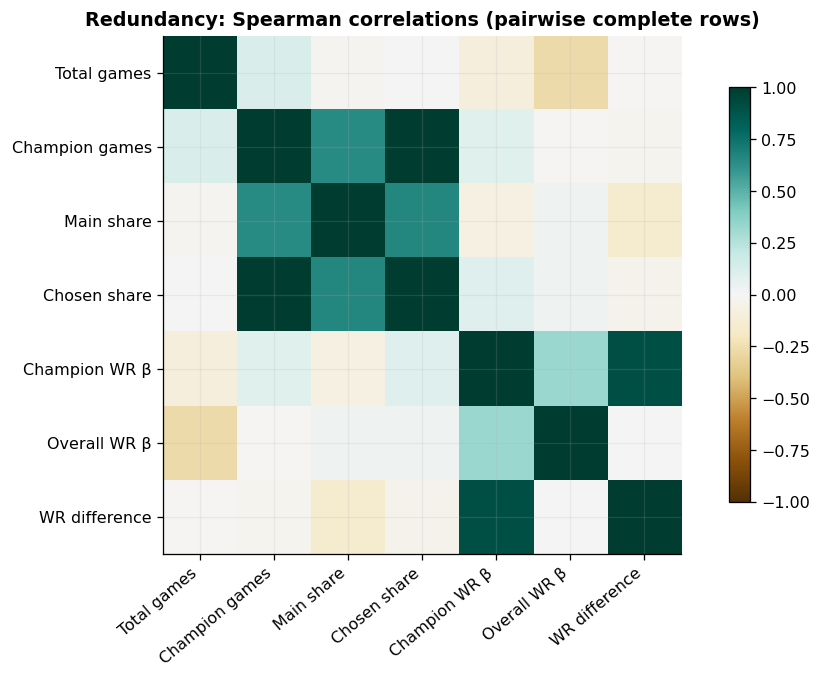

In [12]:
variation=model.groupby('puuid').agg(rows=('win','size'),main_rows=('is_main_champion','sum'),wins=('win','sum'))
variation['off_main_rows']=variation.rows-variation.main_rows
variation['pick_pattern']=np.select([variation.main_rows.eq(0),variation.off_main_rows.eq(0)],
                                   ['Only off-main','Only main'],default='Both')
display(variation.groupby('pick_pattern').agg(players=('rows','size'),target_rows=('rows','sum'),
                     main_rows=('main_rows','sum'),off_main_rows=('off_main_rows','sum')))
print('Players with both target outcomes:', (variation.wins.gt(0)&variation.wins.lt(variation.rows)).sum())
pc=model.groupby(['puuid','champion_id']).agg(rows=('win','size'),wins=('win','sum'))
display(pd.DataFrame([{'minimum_rows_per_player_champion':n,'combinations':int(pc.rows.ge(n).sum()),
       'represented_rows':int(pc.loc[pc.rows.ge(n),'rows'].sum())} for n in [1,2,5,10,20]]))
print('Player/champion combinations with both outcomes:', (pc.wins.gt(0)&pc.wins.lt(pc.rows)).sum())
alt_support=[]
for t in [.4,.5,.6,.7,.8]:
    g=model.loc[model.prior_main_champion_usage_share.ge(t)]
    v=g.groupby('puuid').is_main_champion.agg(['size','sum'])
    alt_support.append({'share_min':f'{t:.0%}','players':len(v),'both_picks':int((v['sum'].gt(0)&v['sum'].lt(v['size'])).sum()),
        'off_main_rows':int((~g.is_main_champion).sum()),
        'off_main_players':g.loc[~g.is_main_champion,'puuid'].nunique()})
display(pd.DataFrame(alt_support))
missingness=model.isna().sum().loc[lambda x:x.gt(0)].rename('missing_rows').to_frame()
missingness['share']=missingness.missing_rows/len(model)
table(missingness,percent=['share'])
continuous=['prior_total_games','prior_champion_games','prior_main_champion_usage_share',
            'prior_champion_usage_share','prior_champion_wr_beta11','prior_overall_wr_beta11',
            'prior_champion_wr_minus_overall']
fig,ax=plt.subplots(figsize=(9,6))
corr=model[continuous].corr(method='spearman')
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='BrBG')
short=['Total games','Champion games','Main share','Chosen share','Champion WR β','Overall WR β','WR difference']
ax.set(xticks=range(len(short)),yticks=range(len(short)),xticklabels=short,yticklabels=short,
       title='Redundancy: Spearman correlations (pairwise complete rows)')
plt.setp(ax.get_xticklabels(),rotation=40,ha='right');fig.colorbar(im,ax=ax,shrink=.8)
plt.tight_layout();plt.show()

Counts, wins, rates and shares encode algebraic redundancies: champion wins/games generate champion WR; main games / total generates specialization; chosen games / total generates chosen share; `is_otp` combines main choice and share. Use a small prespecified predictor set and inspect collinearity rather than include every representation. Raw missing champion WR at zero games is structural: a smoothed feature plus explicit experience indicator is a candidate, not an automatic imputation of the raw rate.

Keep outcome, identifiers, final target counts, completion/coverage flags, future aggregate summaries, latest-end audit fields and postgame performance out of the predictor matrix. Collection flags are useful for sensitivity analyses. Side and champion choices are available before play; `teamPosition` and the derived opponent are postgame inferences and are imperfect proxies for pregame lane assignment. Master membership is unverified. The final predictor design must state which information would actually be available at prediction time.

In [13]:
# Choose approximate 70/15/15 boundaries on UNIQUE MATCHES, not player rows.
# Split by kickoff timestamp so ties cannot leak between partitions.
match_clock=model.groupby('match_id').timestamp.agg(['min','max']).sort_values('min')
if not match_clock['min'].equals(match_clock['max'].rename('min')):
    raise ValueError('Cannot assign chronology: inconsistent shared-match starts')
ordered_starts=match_clock['min'].to_numpy()
cut1=ordered_starts[int(.70*len(ordered_starts))]
cut2=ordered_starts[int(.85*len(ordered_starts))]
split=np.select([model.timestamp.lt(cut1),model.timestamp.lt(cut2)],['train','validation'],default='test')
evaluation=model.assign(partition=split)
partition_table=[]
train_players=set(evaluation.loc[evaluation.partition.eq('train'),'puuid'])
for label in ['train','validation','test']:
    f=evaluation.loc[evaluation.partition.eq(label)]
    partition_table.append({'partition':label,'kickoff_min_UTC':str(utc(f.timestamp.min())),
        'kickoff_max_UTC':str(utc(f.timestamp.max())),'player_games':len(f),
        'unique_matches':f.match_id.nunique(),'players':f.puuid.nunique(),
        'players_seen_in_train':len(set(f.puuid)&train_players),
        'rows_from_players_unseen_in_train':int((~f.puuid.isin(train_players)).sum())})
with pd.option_context('display.max_columns',12,'display.max_colwidth',40):display(pd.DataFrame(partition_table))
assert evaluation.groupby('match_id').partition.nunique().eq(1).all()
print('All rows of every shared match stay in one partition.')
print('Validation starts:',utc(cut1),'| Test starts:',utc(cut2))
# At a boundary, earlier-starting games still in progress may not train a deployable model yet.
fitting_rows=[]
for boundary,label in [(cut1,'validation'),(cut2,'test')]:
    pending=evaluation.loc[evaluation.timestamp.lt(boundary)&evaluation.end_timestamp.ge(boundary)]
    print(f'Earlier-starting rows not completed by {label} boundary: {len(pending)} '
          f'({pending.match_id.nunique()} matches); purge entire such matches from fitting at that boundary.')
    fit=evaluation.loc[evaluation.timestamp.lt(boundary) & ~evaluation.match_id.isin(pending.match_id)]
    fitting_rows.append({'fit_before':label,'completed_player_games':len(fit),'matches':fit.match_id.nunique(),
        'players':fit.puuid.nunique(),'kickoff_min_UTC':str(utc(fit.timestamp.min())),
        'kickoff_max_UTC':str(utc(fit.timestamp.max())),'latest_outcome_UTC':str(utc(fit.end_timestamp.max()))})
print('Deployable fitting sets after purging whole pending matches:')
with pd.option_context('display.max_columns',10,'display.max_colwidth',40):display(pd.DataFrame(fitting_rows))

,partition,kickoff_min_UTC,kickoff_max_UTC,player_games,unique_matches,players,players_seen_in_train,rows_from_players_unseen_in_train
0,train,2026-09-23 12:20:17.734000+00:00,2026-10-02 22:24:44.793000+00:00,5106,4764,178,178,0
1,validation,2026-10-02 22:25:06.238000+00:00,2026-10-05 01:30:36.788000+00:00,1065,1021,129,124,28
2,test,2026-10-05 01:32:18.312000+00:00,2026-10-07 08:33:21.723000+00:00,1067,1021,128,124,8


All rows of every shared match stay in one partition.
Validation starts: 2026-10-02 22:25:06.238000+00:00 | Test starts: 2026-10-05 01:32:18.312000+00:00
Earlier-starting rows not completed by validation boundary: 11 (11 matches); purge entire such matches from fitting at that boundary.
Earlier-starting rows not completed by test boundary: 16 (16 matches); purge entire such matches from fitting at that boundary.
Deployable fitting sets after purging whole pending matches:


,fit_before,completed_player_games,matches,players,kickoff_min_UTC,kickoff_max_UTC,latest_outcome_UTC
0,validation,5095,4753,178,2026-09-23 12:20:17.734000+00:00,2026-10-02 22:01:55.170000+00:00,2026-10-02 22:21:14.154000+00:00
1,test,6155,5769,183,2026-09-23 12:20:17.734000+00:00,2026-10-05 01:12:03.157000+00:00,2026-10-05 01:30:28.516000+00:00


This is a **sequential evaluation** design: fit transformations/model parameters on completed training observations only, tune on validation, then freeze choices for test. At each prediction, earlier completed target outcomes may update the player's features—even earlier validation/test games—because they would already be observed in deployment. Each current outcome stays unavailable until its game ends. Do not update fitted model parameters on validation/test outcomes unless separately evaluating an explicitly online learning policy. Purge whole boundary-overlapping matches before fitting or refitting so their outcomes are available at the cutoff.

This design predominantly evaluates later games from known players. Generalizing to new players requires a separate player-held-out evaluation; shared matches linking held-out and training players need an explicit group-aware exclusion policy. Fixed-origin evaluation, where all later outcomes are withheld until the end, requires reconstructing frozen histories instead of using the saved expanding features. Do not fit final models in this EDA.

## 8. Existing V1 matchup coverage

Inspect the saved V1 Global D2+ patch-16.19 lookup. Join on exact `(lane, champion, opponent_champion)` after selecting patch, rank and region. No name normalization, duplicate aggregation, guessed opponents or 50% fill is applied. Coverage is a descriptive in-memory join only; original observations remain preserved.

V1 source: data/processed/expected_matchups_16_19.parquet | shape: (8572, 16)


,dtype
patch,object
rank,object
region,object
lane,object
champion,object
opponent_champion,object
raw_matchup_winrate,float64
tier_average_winrate,object
lolalytics_delta2,float64
expected_winrate,float64


Duplicate selected lookup-key rows: 0


,lookup_rows
status,
error,175
ok,8397


,rows,players,matches,share
coverage_category,,,,
"Known opponent, external status/rate invalid",7,7,7,0.1%
"Known opponent, key absent",2173,178,2129,30.0%
"Known opponent, usable external rate",5054,184,4815,69.8%
Unidentified lane opponent,4,3,4,0.1%


Known-opponent unique target keys: 4361 | covered: 2620


,min_matchup_games,target_rows,all_target_share,known_opponent_share,players,matches,keys
0,0,5054,69.8%,69.9%,184,4815,2620
1,10,5018,69.3%,69.4%,184,4783,2584
2,25,4950,68.4%,68.4%,184,4722,2526
3,50,4836,66.8%,66.9%,184,4618,2429
4,100,4574,63.2%,63.2%,183,4382,2228
5,200,4041,55.8%,55.9%,182,3889,1842
6,500,2971,41.0%,41.1%,173,2888,1174


Uncovered known-opponent keys: 1741 (largest 15 below)


target_rows  players external_status
lane    champion    opponent_champion                                      
adc     AurelionSol Jinx                         8        3            None
top     Tryndamere  Heimerdinger                 7        1            None
mid     Akshan      Syndra                       7        3            None
                    Akali                        7        3            None
                    Aurora                       7        4            None
        Zoe         Zed                          6        4            None
        Akshan      Katarina                     6        3            None
top     Tryndamere  Garen                        5        1            None
mid     Akshan      Yasuo                        5        3            None
                    Irelia                       5        2            None
        Swain       Zed                          5        1            None
support Senna       Velkoz                       5        2            None
jungle  Talon       MasterYi                     4        1            None
        Zac         Shyvana                      4        1            None
mid     Zoe         Ekko                         4        4            None

,Unique-key sample sizes,Target-row-weighted sample sizes
count,2620.000000,5054.000000
mean,941.450000,1711.479422
std,1477.251664,2556.336972
min,1.000000,1.000000
10%,68.900000,105.000000
25%,166.000000,254.250000
50%,410.500000,695.500000
75%,1124.000000,2038.000000
90%,2263.500000,4692.000000
max,13842.000000,13842.000000


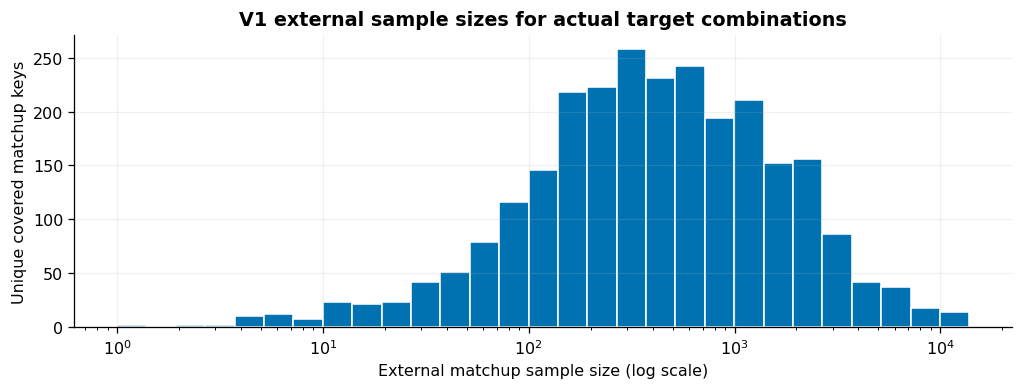

Tier average missing: 8572 / 8572


keys
snapshot_label   status      
2026-10-03       error     22
                 ok      3433
legacy / undated error    153
                 ok      4964

Lookup scrape range: 2026-09-27 00:59:47.927424+00:00 to 2026-10-04 00:46:43.187178+00:00
LIMITATION: External lookup mixes dated/legacy snapshot labels; no uniform final-patch snapshot.


In [14]:
lookup_candidates=[root/f'expected_matchups_16_19.{ext}'
    for root in [ROOT/'data/processed',ROOT/'lpm_model/data/processed'] for ext in ['parquet','csv']]
lookup_path=next((p for p in lookup_candidates if p.exists()),None)
matchup_summary=None
matchup_thresholds=None
matchup_issues=[]
if lookup_path is None:
    print('No V1 lookup found. Needed: patch, rank, region, lane, champion, opponent_champion, '
          'status, expected_winrate, matchup_games, and dated snapshot/provenance. Searched:')
    for p in lookup_candidates: print(p.relative_to(ROOT))
else:
    external=pd.read_parquet(lookup_path) if lookup_path.suffix=='.parquet' else pd.read_csv(lookup_path)
    source_hashes[lookup_path]=hashlib.sha256(lookup_path.read_bytes()).hexdigest()
    print('V1 source:',lookup_path.relative_to(ROOT),'| shape:',external.shape)
    display(external.dtypes.rename('dtype').to_frame())
    KEY=['lane','champion','opponent_champion']
    required={'patch','rank','region','status','expected_winrate','matchup_games',*KEY}
    if not required.issubset(external):
        raise ValueError(f'Missing external schema: {required-set(external)}')
    lookup=external.loc[external.patch.astype(str).eq(config.target_patch)&external['rank'].eq('d2_plus')
                        &external.region.eq('global')].copy()
    duplicates=lookup.duplicated(KEY,keep=False)
    print('Duplicate selected lookup-key rows:',duplicates.sum())
    display(lookup.groupby('status',dropna=False).size().rename('lookup_rows').to_frame())
    if duplicates.any():
        display(lookup.loc[duplicates,KEY+['status']].head(15))
        matchup_issues.append('Duplicate external keys: join and coverage blocked; no silent aggregation.')
        print(matchup_issues[-1])
    else:
        for c in ['expected_winrate','matchup_games']:
            lookup[c]=pd.to_numeric(lookup[c],errors='coerce')
        # Original rates are percent units, not probabilities.
        good=lookup.status.eq('ok') & lookup.expected_winrate.between(0,100) & lookup.matchup_games.gt(0)
        lookup['valid_rate']=good
        joined=model.merge(lookup[KEY+['status','expected_winrate','matchup_games','valid_rate']],
                           on=KEY,how='left',validate='many_to_one',indicator=True)
        assert len(joined)==len(model)
        known=joined.opponent_champion.notna() & joined.lane.notna() & ~joined.matchup_missing
        available=known & joined.valid_rate.eq(True)
        joined['coverage_category']=np.select([~known,known & joined['_merge'].eq('left_only'),available],
            ['Unidentified lane opponent','Known opponent, key absent','Known opponent, usable external rate'],
            default='Known opponent, external status/rate invalid')
        matchup_summary=joined.groupby('coverage_category').agg(rows=('win','size'),players=('puuid','nunique'),
                                                               matches=('match_id','nunique'))
        matchup_summary['share']=matchup_summary.rows/len(model)
        table(matchup_summary,percent=['share'])
        # Unique keys and row-weighted coverage have different denominators.
        known_keys=joined.loc[known,KEY].drop_duplicates()
        print('Known-opponent unique target keys:',len(known_keys),
              '| covered:',joined.loc[available,KEY].drop_duplicates().shape[0])
        thresholds=[]
        for n in [0,10,25,50,100,200,500]:
            keep=available & joined.matchup_games.ge(n)
            thresholds.append({'min_matchup_games':n,'target_rows':int(keep.sum()),
                'all_target_share':keep.mean(),'known_opponent_share':keep.sum()/known.sum(),
                'players':joined.loc[keep,'puuid'].nunique(),'matches':joined.loc[keep,'match_id'].nunique(),
                'keys':joined.loc[keep,KEY].drop_duplicates().shape[0]})
        matchup_thresholds=pd.DataFrame(thresholds)
        table(matchup_thresholds,percent=['all_target_share','known_opponent_share'])
        unmatched=joined.loc[known & ~available].groupby(KEY,dropna=False).agg(
            target_rows=('win','size'),players=('puuid','nunique'),external_status=('status','first')).sort_values('target_rows',ascending=False)
        print('Uncovered known-opponent keys:',len(unmatched),'(largest 15 below)')
        display(unmatched.head(15))
        unique_sizes=joined.loc[available,KEY+['matchup_games']].drop_duplicates(KEY).matchup_games
        display(pd.DataFrame({'Unique-key sample sizes':unique_sizes.describe(percentiles=[.1,.25,.5,.75,.9]),
                              'Target-row-weighted sample sizes':joined.loc[available,'matchup_games'].describe(percentiles=[.1,.25,.5,.75,.9])}))
        fig,ax=plt.subplots(figsize=(9,3.5))
        ax.hist(unique_sizes,bins=np.geomspace(max(1,unique_sizes.min()),unique_sizes.max()+1,30),
                color=BLUE,edgecolor='white')
        ax.set(xscale='log',xlabel='External matchup sample size (log scale)',ylabel='Unique covered matchup keys',
               title='V1 external sample sizes for actual target combinations')
        plt.tight_layout();plt.show()
        print('Tier average missing:',lookup.tier_average_winrate.isna().sum(),'/',len(lookup))
        dated=lookup.assign(snapshot_label=lookup.snapshot_id.fillna('legacy / undated'))
        display(dated.groupby(['snapshot_label','status'],dropna=False).size().rename('keys').to_frame())
        print('Lookup scrape range:',pd.to_datetime(lookup.scraped_at_utc,utc=True).min(),
              'to',pd.to_datetime(lookup.scraped_at_utc,utc=True).max())
        if lookup.snapshot_id.isna().any() or lookup.snapshot_id.dropna().nunique()!=1:
            matchup_issues.append('External lookup mixes dated/legacy snapshot labels; no uniform final-patch snapshot.')
        for issue in matchup_issues: print('LIMITATION:',issue)

`lolalytics_matchup_scraper.parse_matchup_page` computes `expected_winrate = raw_winrate − tier_average_winrate + 50` when a tier average exists, otherwise it uses the raw matchup rate. The raw rate is therefore not necessarily an adjusted estimate. Global D2+ external data also differs from an NA cohort carrying unverified Master labels. Sample size alone does not resolve population mismatch, selection, missing coverage or patch timing.

**Full-patch rates are retrospective**: they include future-in-patch information for earlier games and cannot serve as a time-safe pregame predictor. The locally available table also mixes refresh labels and was scraped during the patch; it must not be presented as a clean final-patch snapshot. A retrospectively labeled analysis may use explicitly documented retrospective context. A predictive analysis needs rates actually available before each game (or a prior-patch / training-only estimate), with dated provenance and a declared policy for uncovered keys. This notebook neither recollects nor imputes them.

## 9. Findings and next steps

The following findings are generated from the executed tables. Intervals and contrasts describe this cohort, not the effect of switching a player's champion.

In [15]:
fail_count=sum(x['status']=='FAIL' for x in checks)
zero=model.prior_champion_games.eq(0)
low=model.prior_champion_games.lt(5)
s50=share_sensitivity.loc[(share_sensitivity.main_share_min.eq('50%')) & share_sensitivity.subset.eq('Specialized player (any pick)')].iloc[0]
s80=share_sensitivity.loc[(share_sensitivity.main_share_min.eq('80%')) & share_sensitivity.subset.eq('Specialized player (any pick)')].iloc[0]
exp10=experience_sensitivity.loc[experience_sensitivity.selected_champion_min_games.eq(10)].iloc[0]
exp30=experience_sensitivity.loc[experience_sensitivity.selected_champion_min_games.eq(30)].iloc[0]
lo,hi=np.quantile(diff_draws.dropna(),[.025,.975])*100
external_finding=('No usable local lookup; obtain the explicitly listed schema and provenance.' if matchup_thresholds is None else
    f'At the no-minimum sample threshold, usable external rates cover **{int(matchup_thresholds.iloc[0].target_rows):,}/{len(model):,} rows '
    f'({matchup_thresholds.iloc[0].all_target_share:.1%})**. Known-opponent missing statistics remain separate from unidentified opponents. '
    + ' '.join(matchup_issues))
findings=f"""
- **Coverage:** {len(cohort):,} sampled players; {model.puuid.nunique():,} represented by {len(model):,} player-games in {model.match_id.nunique():,} target matches; {len(history):,} initial historical rows. Median target games per represented player: {games_per_player.median():.0f}; largest contributor: {games_per_player.max():,}. {len(switcher_rates):,} players are observed on both main and off-main picks.
- **Collection:** {coverage.available_historical_matches.ge(config.historical_depth).sum():,} players reached initial depth; {coverage.genuinely_short_history.sum():,} have exhausted short histories, {coverage.history_incomplete.sum():,} have incomplete history, and {coverage.target_matches.eq(0).sum():,} have no targets. These reconcile {coverage.history_shortfall.gt(0).sum():,} shortfalls. The incomplete player retains {int(incomplete.available_historical_matches.sum())} historical and {int(incomplete.target_matches.sum())} target rows; payload validation failed, but the exact match/upstream cause is unresolved. No Masters labels are dated-verified in this snapshot.
- **Integrity:** {fail_count} failed checks among {len(checks)} recorded audits. Counts/wins and all pure-helper features were reconstructed from preserved records; this does not prove API completeness. Four missing-opponent rows have confirmed role-assignment causes in local caches. Keep them for experience summaries; omit them from opponent-dependent analysis.
- **Experience:** {int(zero.sum()):,} target picks ({zero.mean():.1%}) have zero selected-champion history; {int(low.sum()):,} ({low.mean():.1%}) have fewer than five games. Median selected-champion experience is {model.prior_champion_games.median():.0f}; median initial distinct champions is {first.initial_distinct_champions.median():.0f}. Smoothing tempers extremes without fixing sparse history.
- **Performance:** main win rate is {pick_summary.loc['Main','win_rate']:.1%}, off-main {pick_summary.loc['Off-main','win_rate']:.1%}; game-weighted difference {main_diff*100:.2f} pp (player-cluster interval {lo:.2f} to {hi:.2f} pp). Equal-player rates are {pick_summary.loc['Main','equal_player_wr']:.1%} and {pick_summary.loc['Off-main','equal_player_wr']:.1%}. Read the experience, historical-WR and proficiency-proxy bin tables alongside their player counts. No causal champion-switching conclusion follows; shared matches remain an uncertainty limitation.
- **Specialization / alternatives:** the 50% share definition retains {int(s50.target_rows):,} rows / {int(s50.players):,} players, with {int(s50.off_main_rows):,} alternative rows / {int(s50.off_main_players):,} alternative-pick players. At 80%, only {int(s80.target_rows):,} rows / {int(s80.players):,} players and {int(s80.off_main_rows):,} alternatives remain. {int(pc.rows.eq(1).sum()):,}/{len(pc):,} player–champion combinations occur only once. Player effects have repeated observations; player–champion effects require strong partial pooling and sparse-group review.
- **Candidate thresholds:** compare 40/50/60% specialization and 5/10/20-game experience definitions without committing now. A 10-game experience screen retains {int(exp10.target_rows):,} rows and {int(exp10.off_main_rows):,} alternative picks; 30 games retains {int(exp30.target_rows):,} and {int(exp30.off_main_rows):,}, illustrating lost comparison support. Keep continuous experience and specialization as primary candidates, with explicit zero-experience handling.
- **Matchup integration:** {external_finding} Full-patch and mixed in-patch scraped rates do not provide time-safe pregame predictors. Resolve dated coverage and rate semantics before modeling disadvantage; do not fill missing rates with 50%.
- **Next modeling steps:** prespecify a small, nonredundant logistic baseline, then player-intercept hierarchical logistic regression; add player–champion terms only with shrinkage/support checks. Use the chronological partitions above with shared-match grouping, boundary purging and sequential pregame updates. Compare incomplete-history and threshold sensitivities. Evaluate calibration and discrimination in later games; assess unseen-player transfer separately. Observational confounding, role inference, incomplete external coverage and unverified rank remain unresolved.
"""
display(Markdown(findings))
changed=[str(p.relative_to(ROOT)) for p,digest in source_hashes.items()
         if hashlib.sha256(p.read_bytes()).hexdigest()!=digest]
print('Protected local inputs changed during notebook:',changed)
assert not changed


- **Coverage:** 200 sampled players; 185 represented by 7,238 player-games in 6,806 target matches; 29,889 initial historical rows. Median target games per represented player: 27; largest contributor: 197. 160 players are observed on both main and off-main picks.
- **Collection:** 159 players reached initial depth; 25 have exhausted short histories, 1 have incomplete history, and 15 have no targets. These reconcile 41 shortfalls. The incomplete player retains 119 historical and 5 target rows; payload validation failed, but the exact match/upstream cause is unresolved. No Masters labels are dated-verified in this snapshot.
- **Integrity:** 0 failed checks among 33 recorded audits. Counts/wins and all pure-helper features were reconstructed from preserved records; this does not prove API completeness. Four missing-opponent rows have confirmed role-assignment causes in local caches. Keep them for experience summaries; omit them from opponent-dependent analysis.
- **Experience:** 411 target picks (5.7%) have zero selected-champion history; 1,453 (20.1%) have fewer than five games. Median selected-champion experience is 25; median initial distinct champions is 20. Smoothing tempers extremes without fixing sparse history.
- **Performance:** main win rate is 51.9%, off-main 49.4%; game-weighted difference 2.50 pp (player-cluster interval 0.20 to 4.85 pp). Equal-player rates are 49.7% and 46.4%. Read the experience, historical-WR and proficiency-proxy bin tables alongside their player counts. No causal champion-switching conclusion follows; shared matches remain an uncertainty limitation.
- **Specialization / alternatives:** the 50% share definition retains 2,661 rows / 77 players, with 734 alternative rows / 72 alternative-pick players. At 80%, only 1,022 rows / 31 players and 127 alternatives remain. 879/1,728 player–champion combinations occur only once. Player effects have repeated observations; player–champion effects require strong partial pooling and sparse-group review.
- **Candidate thresholds:** compare 40/50/60% specialization and 5/10/20-game experience definitions without committing now. A 10-game experience screen retains 4,961 rows and 1,981 alternative picks; 30 games retains 3,408 and 571, illustrating lost comparison support. Keep continuous experience and specialization as primary candidates, with explicit zero-experience handling.
- **Matchup integration:** At the no-minimum sample threshold, usable external rates cover **5,054/7,238 rows (69.8%)**. Known-opponent missing statistics remain separate from unidentified opponents. External lookup mixes dated/legacy snapshot labels; no uniform final-patch snapshot. Full-patch and mixed in-patch scraped rates do not provide time-safe pregame predictors. Resolve dated coverage and rate semantics before modeling disadvantage; do not fill missing rates with 50%.
- **Next modeling steps:** prespecify a small, nonredundant logistic baseline, then player-intercept hierarchical logistic regression; add player–champion terms only with shrinkage/support checks. Use the chronological partitions above with shared-match grouping, boundary purging and sequential pregame updates. Compare incomplete-history and threshold sensitivities. Evaluate calibration and discrimination in later games; assess unseen-player transfer separately. Observational confounding, role inference, incomplete external coverage and unverified rank remain unresolved.


Protected local inputs changed during notebook: []
